In [1]:
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_5348\1871147362.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun


In [8]:
api_wrapper_arxiv=ArxivAPIWrapper(top_k_results=2,doc_content_chars_max=500)
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv)
print(arxiv.name)

arxiv


In [9]:
result=arxiv.invoke("Attention iss all you need")
print(result)

AttributeError: 'Search' object has no attribute 'results'

In [3]:
api_wrapper_wiki=WikipediaAPIWrapper(top_k_results=1,doc_content_chars_max=500)
wiki=WikipediaQueryRun(api_wrapper=api_wrapper_wiki)
wiki.name

'wikipedia'

In [6]:
result = wiki.invoke("Artificial Intelligence")
print(result)

Page: Artificial intelligence
Summary: Artificial intelligence (AI) is the capability of computational systems to perform tasks typically associated with human intelligence, such as learning, reasoning, problem-solving, perception, and decision-making. It is also a field of research spanning computer science, engineering, and mathematics that develops and studies methods and software enabling machines to perceive their environment and use learning and intelligence to take actions that maximise t


In [10]:
from dotenv import load_dotenv
load_dotenv()

import os

os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")


In [11]:
from langchain_community.tools.tavily_search import TavilySearchResults

tavily = TavilySearchResults()

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_5348\735679136.py:3: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults()


In [12]:
tavily.invoke("Provide me the recent AI news for 1 Nov 2026")

[{'title': 'AI News Today, November 1: Top Stories | AI Weekly',
  'url': 'https://aiweekly.co/ai-news-today',
  'content': "A Memdoor workflow reproducing the GVS5H harness (Lee, 2026) runs five Qwen3.8-27B models as planner, two ideators, solver, manager and a repair worker — communicating only through files on disk — and scored a mean 9.8/10 on the first ten LiveCodeBench Hard problems vs 8.0 for Claude Fable 5 alone. Across 50 total runs the team solved 49/50 problems using 15.3M output tokens at $35.79, a fraction of Fable 5 pricing. The HN thread drew scrutiny over whether shared files leak intermediate solutions between agents.\n\ntwitter.com 5h ago 22\n\nAnthropic flags HK PhD for 'training a competitor' without distilling Claude [...] Dreamgroup researchers detail a Chinese-nexus campaign that chained PHP2Shell (CVE-2026-109618/109619 on PAN-OS management web server) with the Fragnesia kernel LPE (CVE-2026-46300) to root 24 firewalls plus one internal management box in US, Jap

In [17]:
tools=[arxiv,wiki,tavily]

In [18]:
from langchain_groq import ChatGroq

llm=ChatGroq(model="qwen/qwen3.8-27b")

llm_with_tools=llm.bind_tools(tools)

In [19]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")])

AIMessage(content="Here is a summary of the most recent and significant AI news as of **May 2024**:\n\n### 1. **OpenAI’s GPT-4o (Omni) Launch**\n- **What:** OpenAI released **GPT-4o**, a new multimodal model that can process and generate text, audio, and images in real-time. It was unveiled at the “OpenAI DevDay” in October 2024 (note: if you're looking for *very* recent news, this was a major recent event; however, as of May 2024, GPT-4o was not yet released—please see correction below).\n- **Correction:** As of **May 2024**, OpenAI’s most recent major release was **GPT-4 Turbo** and the ongoing rollout of **GPTs** (custom GPTs). The highly anticipated **GPT-4o** was actually released in **May 2024** (specifically, it was announced on **May 13, 2024**).\n- **Key Feature:** GPT-4o is the first model to handle **real-time voice conversations** with human-like latency (~320ms response time), making it a significant step toward natural human-AI interaction.\n- **Impact:** It competes dire

In [20]:
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")]).tool_calls

[{'name': 'tavily_search_results_json',
  'args': {'query': 'latest AI news this week 2025'},
  'id': 'qv3sjew1c',
  'type': 'tool_call'}]

In [21]:
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

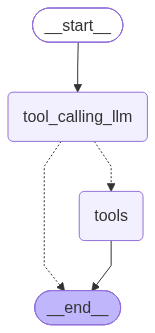

In [22]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools", END)


graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))


In [24]:
messages=graph.invoke({"messages":HumanMessage(content="Provide me the top 10 recent AI news for MArch 3rd 2025")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news for MArch 3rd 2025
================================== Ai Message ==================================

I'll search for recent AI news from around March 3rd, 2025. Let me run several searches in parallel to gather comprehensive results.
Tool Calls:
  tavily_search_results_json (bqevegee5)
 Call ID: bqevegee5
  Args:
    query: top AI news March 3 2025
  tavily_search_results_json (7ymnt54wz)
 Call ID: 7ymnt54wz
  Args:
    query: artificial intelligence announcements March 2025
  tavily_search_results_json (wkk01c9h2)
 Call ID: wkk01c9h2
  Args:
    query: AI model release news early March 2025
  tavily_search_results_json (5d4sx8y0b)
 Call ID: 5d4sx8y0b
  Args:
    query: OpenAI Google Anthropic news March 2025
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "The 10 Biggest AI News Stories Of 2

In [25]:
messages=graph.invoke({"messages":HumanMessage(content="What is machine learning")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is machine learning
================================== Ai Message ==================================

Machine learning is a core subfield of **artificial intelligence (AI)** that focuses on building systems capable of learning and improving from experience without being explicitly programmed for every task.

In traditional programming, you provide a computer with a set of rules and data, and it produces an output. In machine learning, you provide the computer with data and the desired output, and it **learns the rules (patterns) on its own**.

### Key Components:
1. **Data**: The fuel for machine learning. The more high-quality data, the better the model typically performs.
2. **Model**: The mathematical representation or algorithm that learns from the data.
3. **Training**: The process of adjusting the model’s parameters based on the data to minimize errors.
4. **Inference**: Using the trained model